In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score, StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             balanced_accuracy_score, f1_score, roc_auc_score,
                             average_precision_score)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from optuna.samplers import TPESampler
import optuna
from cross_validation_utils import (
    CV_PROTOCOL, split_summary, evaluate_cv, nested_cv,
    print_cv_metrics, summary_row, save_cv_result
)


In [50]:
df = pd.read_csv('sylhet_diabetes.csv')
df.head()

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


In [51]:
df.tail()

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
515,39,Female,Yes,Yes,Yes,No,Yes,No,No,Yes,No,Yes,Yes,No,No,No,Positive
516,48,Female,Yes,Yes,Yes,Yes,Yes,No,No,Yes,Yes,Yes,Yes,No,No,No,Positive
517,58,Female,Yes,Yes,Yes,Yes,Yes,No,Yes,No,No,No,Yes,Yes,No,Yes,Positive
518,32,Female,No,No,No,Yes,No,No,Yes,Yes,No,Yes,No,No,Yes,No,Negative
519,42,Male,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Negative


In [52]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Age                 520 non-null    int64
 1   Gender              520 non-null    str  
 2   Polyuria            520 non-null    str  
 3   Polydipsia          520 non-null    str  
 4   sudden weight loss  520 non-null    str  
 5   weakness            520 non-null    str  
 6   Polyphagia          520 non-null    str  
 7   Genital thrush      520 non-null    str  
 8   visual blurring     520 non-null    str  
 9   Itching             520 non-null    str  
 10  Irritability        520 non-null    str  
 11  delayed healing     520 non-null    str  
 12  partial paresis     520 non-null    str  
 13  muscle stiffness    520 non-null    str  
 14  Alopecia            520 non-null    str  
 15  Obesity             520 non-null    str  
 16  class               520 non-null    str  
dtypes: int64

In [53]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,520.0,NaN,NaN,NaN,48.028846,12.151466,16.0,39.0,47.5,57.0,90.0
Gender,520,2,Male,328,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Polyuria,520,2,No,262,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Polydipsia,520,2,No,287,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sudden weight loss,520,2,No,303,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weakness,520,2,Yes,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Polyphagia,520,2,No,283,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genital thrush,520,2,No,404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visual blurring,520,2,No,287,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Itching,520,2,No,267,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [54]:
df['class'].value_counts()

class
Positive    320
Negative    200
Name: count, dtype: int64

In [55]:
df['class'].value_counts(normalize=True) * 100

class
Positive    61.538462
Negative    38.461538
Name: proportion, dtype: float64

In [56]:
symptom_columns = [
    'Polyuria', 'Polydipsia', 'sudden weight loss', 'weakness',
    'Polyphagia', 'Genital thrush', 'visual blurring', 'Itching',
    'Irritability', 'delayed healing', 'partial paresis',
    'muscle stiffness', 'Alopecia', 'Obesity'
]

# Encoding ini bersifat tetap dan tidak mempelajari statistik dari data.
df[symptom_columns] = df[symptom_columns].apply(
    lambda column: column.str.strip().map({'No': 0, 'Yes': 1})
)
df['Gender'] = df['Gender'].str.strip().map({'Female': 0, 'Male': 1})
df['class'] = df['class'].str.strip().map({'Negative': 0, 'Positive': 1})

assert not df.isna().any().any(), 'Ada kategori yang gagal diencoding.'
print(f'Total missing values: {df.isna().sum().sum()}')
print(f'Exact duplicate rows: {df.duplicated().sum()}')
print('Duplicates are retained; identical profiles are assigned to the same split group.')

Total missing values: 0
Exact duplicate rows: 269
Duplicates are retained; identical profiles are assigned to the same split group.


In [57]:
# Pairplot 16 fitur dinonaktifkan agar notebook tetap ringan.
# Jika diperlukan, aktifkan pada sampel kecil:
# sns.pairplot(df.sample(min(250, len(df)), random_state=42), hue='class')

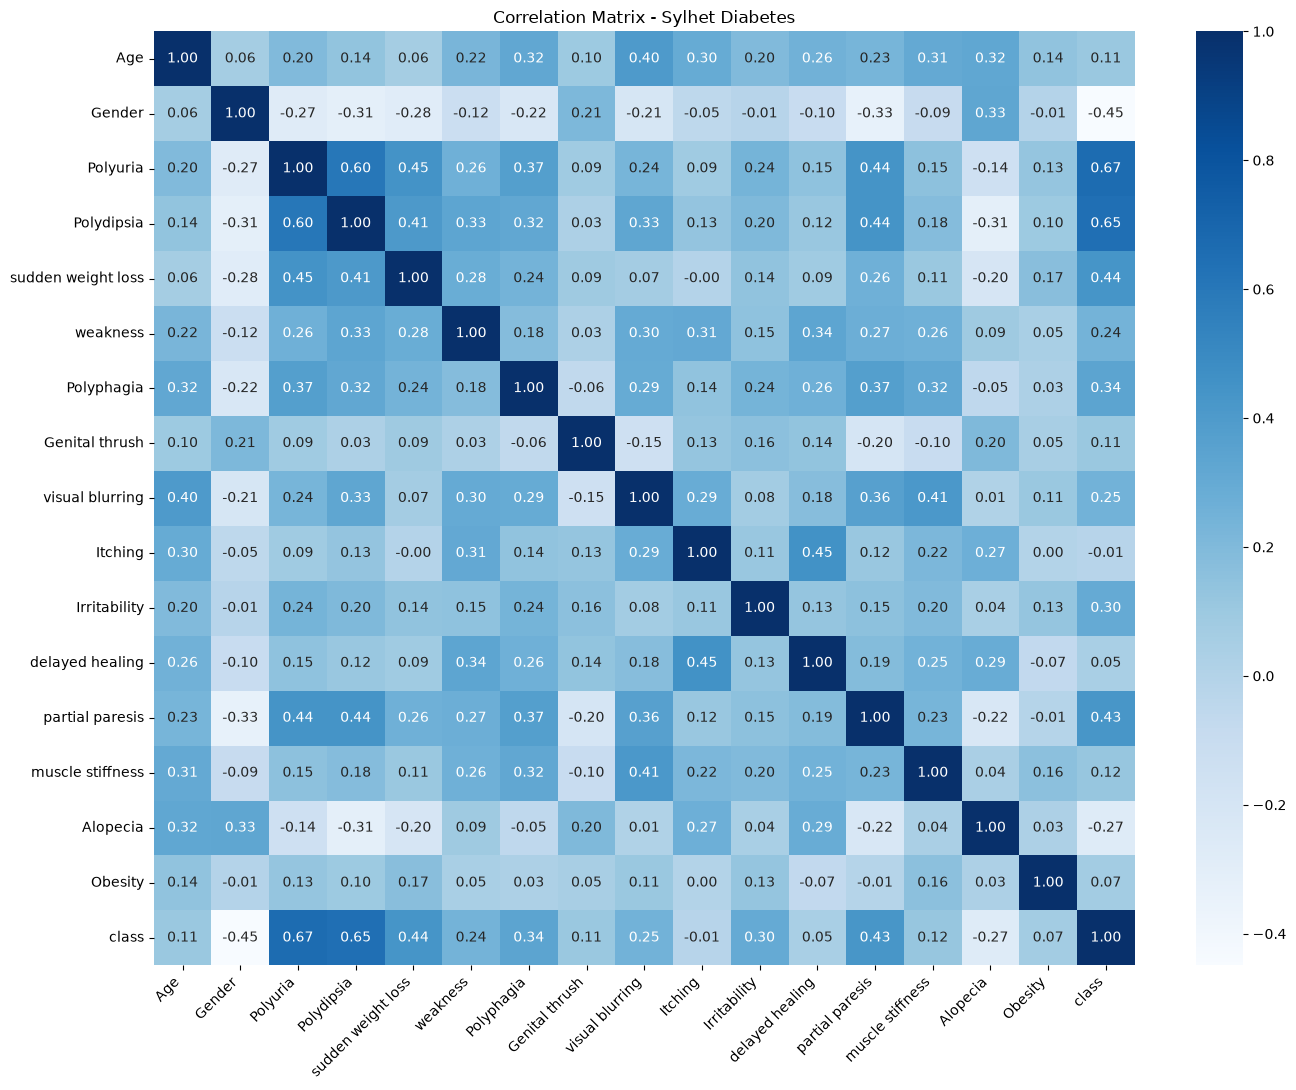

In [58]:
plt.figure(figsize=(14, 11))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='Blues')
plt.xticks(rotation=45, ha='right')
plt.title('Correlation Matrix - Sylhet Diabetes')
plt.tight_layout()
plt.show()

In [59]:
X = df.drop('class', axis=1)
y = df['class'].astype(int)

# Baris dengan profil fitur identik diberi group ID yang sama.
groups = X.groupby(list(X.columns), sort=False, dropna=False).ngroup()
profile_label_counts = df.groupby(
    list(X.columns), sort=False, dropna=False
)['class'].nunique()
assert profile_label_counts.max() == 1, 'Ada profil identik dengan label yang bertentangan.'
print(f'Number of rows       : {len(df)}')
print(f'Unique profiles      : {groups.nunique()}')
print(f'Conflicting profiles : {(profile_label_counts > 1).sum()}')

Number of rows       : 520
Unique profiles      : 251
Conflicting profiles : 0


In [60]:
RANDOM_STATE = 42

N_SPLITS = 5

outer_cv = StratifiedGroupKFold(
    n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE
)

# Seluruh fold dipakai; setiap baris menjadi validation tepat sekali.
split_summary(X, y, outer_cv, groups)


,Fold,Train,Validation,Positif train,Positif validation
0,1,416,104,256,64
1,2,416,104,256,64
2,3,416,104,256,64
3,4,416,104,256,64
4,5,416,104,256,64


In [61]:
cv = StratifiedGroupKFold(
    n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE
)

def make_pipeline(xgb_params):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('smote', SMOTE(sampling_strategy='minority', random_state=RANDOM_STATE)),
        ('xgb', XGBClassifier(
            objective='binary:logistic',
            eval_metric='logloss',
            tree_method='hist',
            device='cuda',
            random_state=RANDOM_STATE,
            n_jobs=1,
            **xgb_params
        ))
    ])

In [62]:
baseline_params = {
    'max_depth': 3,
    'learning_rate': 0.1,
    'n_estimators': 100,
    'reg_alpha': 0.0,
    'reg_lambda': 1.0
}

In [63]:
baseline_pipeline = make_pipeline(baseline_params)
baseline_cv = evaluate_cv(
    make_pipeline, baseline_params, X, y, outer_cv, groups
)


Outer fold 1/5: train=416, validation=104
Outer fold 2/5: train=416, validation=104
Outer fold 3/5: train=416, validation=104
Outer fold 4/5: train=416, validation=104
Outer fold 5/5: train=416, validation=104


In [64]:
# Prediksi out-of-fold: bukan prediksi pada data latih.
y_pred = baseline_cv['prediction']
y_proba = baseline_cv['probability']


In [65]:
print_cv_metrics(baseline_cv)
print('\nClassification Report (OOF Predictions):')
print(classification_report(y, y_pred, target_names=['Negative', 'Positive'], zero_division=0))


Mean per fold:
Accuracy          : 0.9019 +/- 0.0779
Balanced Accuracy : 0.8997 +/- 0.0874
Precision         : 0.9335 +/- 0.0777
Recall            : 0.9094 +/- 0.0639
Specificity       : 0.8900 +/- 0.1399
F1                : 0.9200 +/- 0.0615
ROC-AUC           : 0.9609 +/- 0.0331
PR-AUC            : 0.9791 +/- 0.0159

Classification Report (OOF Predictions):
              precision    recall  f1-score   support

    Negative       0.86      0.89      0.87       200
    Positive       0.93      0.91      0.92       320

    accuracy                           0.90       520
   macro avg       0.89      0.90      0.90       520
weighted avg       0.90      0.90      0.90       520



Combined OOF confusion matrix (5 folds): 520 samples.


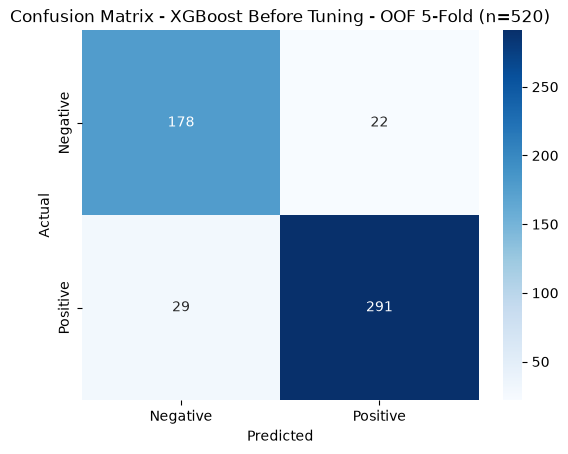

In [66]:
# Confusion matrix gabungan prediksi OOF seluruh outer folds.
# Setiap baris diuji sekali; skor utama tetap mean +/- std antar-fold.
print(f'Combined OOF confusion matrix ({N_SPLITS} folds): {len(y)} samples.')

sns.heatmap(
    confusion_matrix(y, y_pred), annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)
plt.title(f'Confusion Matrix - XGBoost Before Tuning - OOF {N_SPLITS}-Fold (n={len(y)})')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [67]:
def objective(trial, X_train=X, y_train=y, cv=cv, groups_train=groups):
    trial_params = {
        'max_depth': trial.suggest_int('max_depth', 2, 6),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.30, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 50, 400, step=50),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0, step=0.1),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0, step=0.1),
        'gamma': trial.suggest_float('gamma', 0.0, 5.0, step=0.25),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-6, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 20.0, log=True)
    }
    pipeline = make_pipeline(trial_params)
    scores = cross_val_score(
        pipeline, X_train, y_train, groups=groups_train,
        cv=cv, scoring='f1', n_jobs=1
    )
    return scores.mean()

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 50

# Evaluasi seluruh outer folds; tuning hanya melihat inner training folds.
tuned_cv = nested_cv(
    objective, make_pipeline, X, y, outer_cv, cv,
    n_trials=N_TRIALS, groups=groups, random_state=RANDOM_STATE
)

# Cari parameter model final pada seluruh data setelah evaluasi selesai.
# Model refit ini untuk LIME/deployment, bukan untuk menghitung skor OOF.
study = optuna.create_study(
    direction='maximize', sampler=TPESampler(seed=RANDOM_STATE)
)
study.optimize(objective, n_trials=N_TRIALS)

Outer fold 1/5: train=416, validation=104
Outer fold 2/5: train=416, validation=104
Outer fold 3/5: train=416, validation=104
Outer fold 4/5: train=416, validation=104
Outer fold 5/5: train=416, validation=104


In [68]:
print('Best Params:', study.best_params)
print(f'Best mean group-CV F1: {study.best_value:.4f}')

# Simpan hasil tuning agar otomatis digunakan notebook perbandingan.
import json
from pathlib import Path

params_path = Path('best_params_sylhet.json')
tuning_results = (
    json.loads(params_path.read_text(encoding='utf-8'))
    if params_path.exists() else {}
)
# Simpan prediksi dan metrik outer folds untuk notebook komparasi.
cv_result_file = save_cv_result(
    tuned_cv, X, y, groups,
    Path('cv_results/xgboost_sylhet.json.gz'), study.best_params
)
outer_scores = summary_row(tuned_cv)
tuning_results['XGBoost'] = {
    'params': study.best_params,
    'cv_f1': float(study.best_value),
    'outer_cv_f1': outer_scores['F1'],
    'outer_cv_f1_std': outer_scores['F1 Std'],
    'evaluation_protocol': CV_PROTOCOL,
    'outer_n_splits': N_SPLITS,
    'inner_n_splits': N_SPLITS,
    'cv_result_file': cv_result_file
}
params_path.write_text(
    json.dumps(tuning_results, indent=2), encoding='utf-8'
)
print(f'Best XGBoost parameters saved to: {params_path.resolve()}')

# Refit pada seluruh data setelah evaluasi; skor tetap dari prediksi OOF.
best_pipeline = make_pipeline(study.best_params)
best_pipeline.fit(X, y)

Best Params: {'max_depth': 4, 'learning_rate': 0.08135428807971634, 'n_estimators': 100, 'min_child_weight': 3, 'subsample': 0.7, 'colsample_bytree': 0.7, 'gamma': 0.0, 'reg_alpha': 0.03702571041835466, 'reg_lambda': 0.0013076787602647754}
Best mean group-CV F1: 0.9379
Best XGBoost parameters saved to: D:\TELKOM\PENPRO\Diabetes\Model\temp\best_params_sylhet.json


,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](16,)","['Age','Gender','Polyuria',...,'muscle stiffness','Alopecia','Obesity']"
n_features_in_,int,16
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None


In [69]:
optuna_prediction = tuned_cv['prediction']
optuna_proba = tuned_cv['probability']

print_cv_metrics(tuned_cv)
print('\nClassification Report (OOF Predictions):')
print(classification_report(y, optuna_prediction, target_names=['Negative', 'Positive'], zero_division=0))


Mean per fold:
Accuracy          : 0.9019 +/- 0.0399
Balanced Accuracy : 0.8912 +/- 0.0469
Precision         : 0.9097 +/- 0.0507
Recall            : 0.9375 +/- 0.0552
Specificity       : 0.8450 +/- 0.1022
F1                : 0.9216 +/- 0.0314
ROC-AUC           : 0.9689 +/- 0.0201
PR-AUC            : 0.9820 +/- 0.0111

Classification Report (OOF Predictions):
              precision    recall  f1-score   support

    Negative       0.89      0.84      0.87       200
    Positive       0.91      0.94      0.92       320

    accuracy                           0.90       520
   macro avg       0.90      0.89      0.90       520
weighted avg       0.90      0.90      0.90       520



In [70]:
baseline_scores = summary_row(baseline_cv)
tuned_scores = summary_row(tuned_cv)

for metric in ['Accuracy', 'F1']:
    print(f"Baseline {metric}: {baseline_scores[metric]:.4f} +/- "
          f"{baseline_scores[f'{metric} Std']:.4f}")
    print(f"Tuned {metric}   : {tuned_scores[metric]:.4f} +/- "
          f"{tuned_scores[f'{metric} Std']:.4f}")


Baseline Accuracy: 0.9019 +/- 0.0779
Tuned Accuracy   : 0.9019 +/- 0.0399
Baseline F1: 0.9200 +/- 0.0615
Tuned F1   : 0.9216 +/- 0.0314


Combined OOF confusion matrix (5 folds): 520 samples.


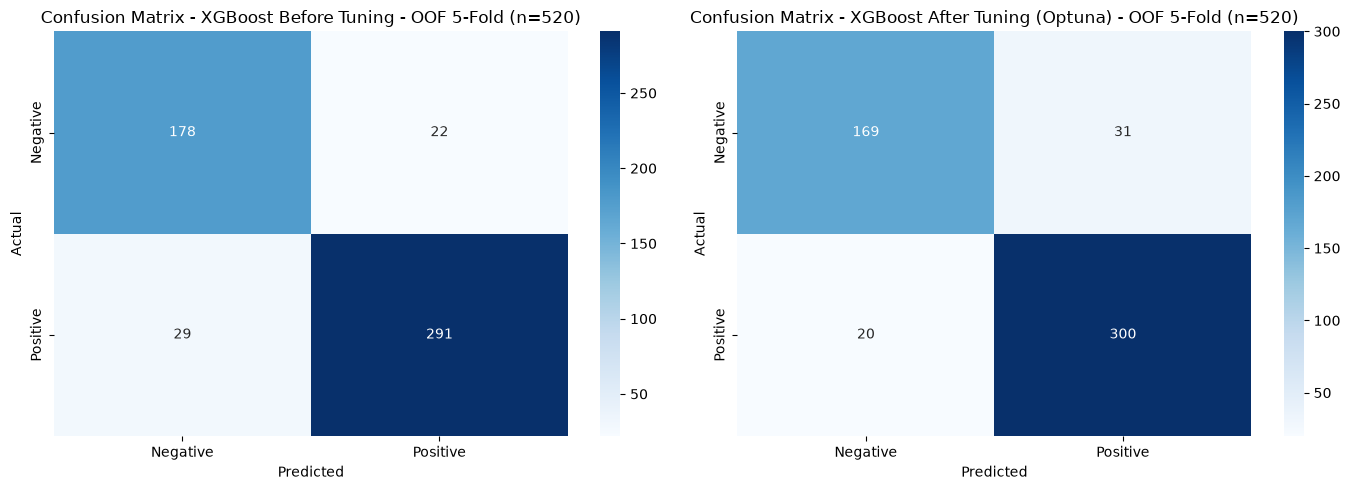

In [71]:
# Confusion matrix gabungan prediksi OOF seluruh outer folds.
# Setiap baris diuji sekali; skor utama tetap mean +/- std antar-fold.
assert np.array_equal(baseline_cv['fold_id'], tuned_cv['fold_id']), \
    'Fold baseline dan tuning harus identik.'
print(f'Combined OOF confusion matrix ({N_SPLITS} folds): {len(y)} samples.')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    confusion_matrix(y, y_pred), annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive'], ax=ax[0]
)
ax[0].set_title(f'Confusion Matrix - XGBoost Before Tuning - OOF {N_SPLITS}-Fold (n={len(y)})')
ax[0].set_xlabel('Predicted')
ax[0].set_ylabel('Actual')

sns.heatmap(
    confusion_matrix(y, optuna_prediction), annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive'], ax=ax[1]
)
ax[1].set_title(f'Confusion Matrix - XGBoost After Tuning (Optuna) - OOF {N_SPLITS}-Fold (n={len(y)})')
ax[1].set_xlabel('Predicted')
ax[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [72]:
# Variasi antar-fold; bukan bootstrap test set atau confidence interval.
fold_scores = tuned_cv['folds']['Accuracy'].to_numpy()
mean_acc = fold_scores.mean()
std_acc = fold_scores.std(ddof=1)

print(f'Mean Accuracy ({N_SPLITS}-Fold CV): {mean_acc:.4f} +/- {std_acc:.4f}')
tuned_cv['folds'].drop(columns='Best Params').round(4)


Mean Accuracy (5-Fold CV): 0.9019 +/- 0.0399


,Fold,Train Rows,Validation Rows,Accuracy,Balanced Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC,Fit seconds,Inner CV F1
0,1,416,104,0.8558,0.8219,0.8267,0.9688,0.675,0.8921,0.9496,0.9707,47.6882,0.9490
1,2,416,104,0.9327,0.9266,0.9385,0.9531,0.900,0.9457,0.9676,0.9781,42.1202,0.9445
2,3,416,104,0.9519,0.9422,0.9403,0.9844,0.900,0.9618,0.9949,0.9969,83.4614,0.9104
3,4,416,104,0.8942,0.8812,0.8955,0.9375,0.825,0.9160,0.9828,0.9899,104.6473,0.9273
4,5,416,104,0.8750,0.8844,0.9474,0.8438,0.925,0.8926,0.9496,0.9741,45.2327,0.9424


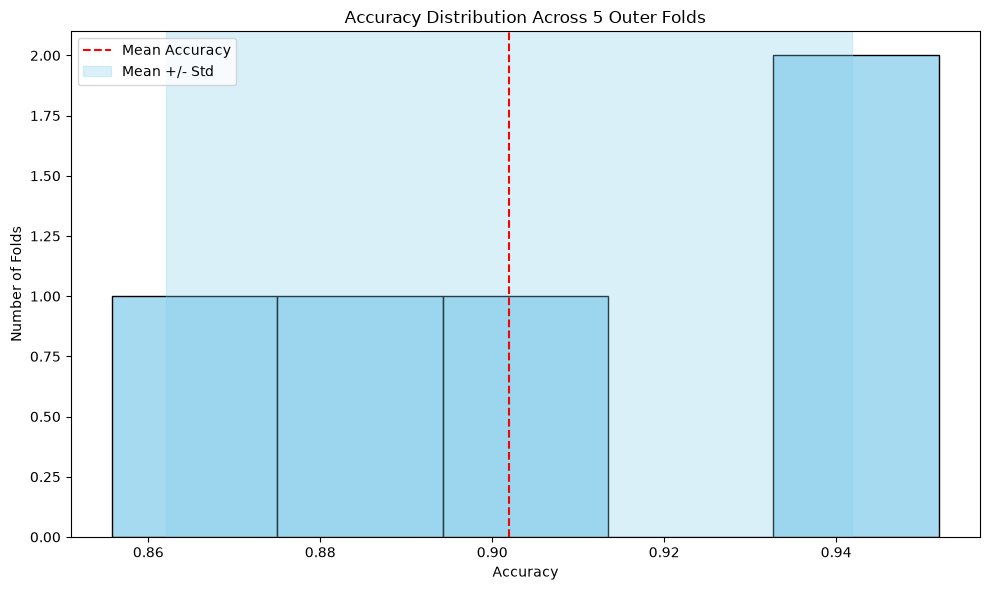

In [73]:
plt.figure(figsize=(10, 6))
sns.histplot(fold_scores, bins=N_SPLITS, color='skyblue')
plt.axvline(mean_acc, color='red', linestyle='--', label='Mean Accuracy')
plt.axvspan(mean_acc - std_acc, mean_acc + std_acc,
            color='skyblue', alpha=0.3, label='Mean +/- Std')
plt.title(f'Accuracy Distribution Across {N_SPLITS} Outer Folds')
plt.xlabel('Accuracy')
plt.ylabel('Number of Folds')
plt.legend()
plt.tight_layout()
plt.show()


In [74]:
from lime.lime_tabular import LimeTabularExplainer

In [75]:
# LIME menggunakan model final yang sudah direfit pada seluruh data.
X_imputed = pd.DataFrame(
    best_pipeline.named_steps['imputer'].transform(X),
    columns=X.columns, index=X.index
)

categorical_indices = [
    index for index, column in enumerate(X.columns) if column != 'Age'
]
categorical_names = {
    X.columns.get_loc('Gender'): ['Female', 'Male']
}
for column in symptom_columns:
    categorical_names[X.columns.get_loc(column)] = ['No', 'Yes']

explainer = LimeTabularExplainer(
    training_data=X_imputed.values,
    feature_names=X.columns.tolist(),
    class_names=['Negative', 'Positive'],
    categorical_features=categorical_indices,
    categorical_names=categorical_names,
    mode='classification',
    random_state=RANDOM_STATE
)

In [76]:
# Nomor data yang sama dipakai di semua notebook model Sylhet.
sample = 10  # Nomor urut dimulai dari 1.
assert 1 <= sample <= len(X), 'Nomor sampel di luar jumlah data.'
sample_index = sample - 1

sample_data = X.iloc[sample_index]
sample_data_imputed = best_pipeline.named_steps['imputer'].transform(
    sample_data.to_frame().T
)[0]

def lime_predict(data):
    data_df = pd.DataFrame(data, columns=X.columns)
    return best_pipeline.predict_proba(data_df)

exp = explainer.explain_instance(
    data_row=sample_data_imputed,
    predict_fn=lime_predict,
    num_features=8
)

In [77]:
from IPython.display import HTML, display

html_output = exp.as_html(show_table=True, show_all=False)
actual_label = 'Positive' if y.iloc[sample_index] == 1 else 'Negative'
print(f'Actual value for sample {sample} (index {sample_index}): {actual_label}')
display(HTML(html_output))


Actual value for sample 10 (index 9): Positive


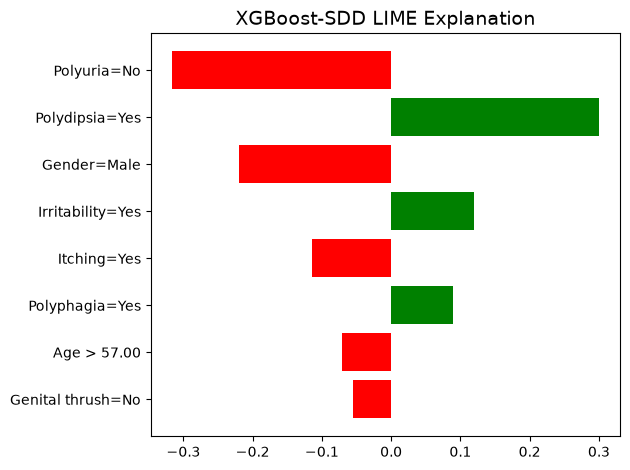

LIME image saved to: D:\TELKOM\PENPRO\Diabetes\Model\temp\lime_xgboost_sylhet.png


In [78]:
from pathlib import Path

output_path = Path('lime_xgboost_sylhet.png')

label = exp.available_labels()[0]
fig = exp.as_pyplot_figure(label=label)
fig.axes[0].set_title('XGBoost-SDD LIME Explanation', fontsize=14)

fig.tight_layout()
fig.savefig(
    output_path,
    format='png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
print(f'LIME image saved to: {output_path.resolve()}')
